Loading dataset...
Chart successfully saved as 'frogs_conservation_diversity.png'!


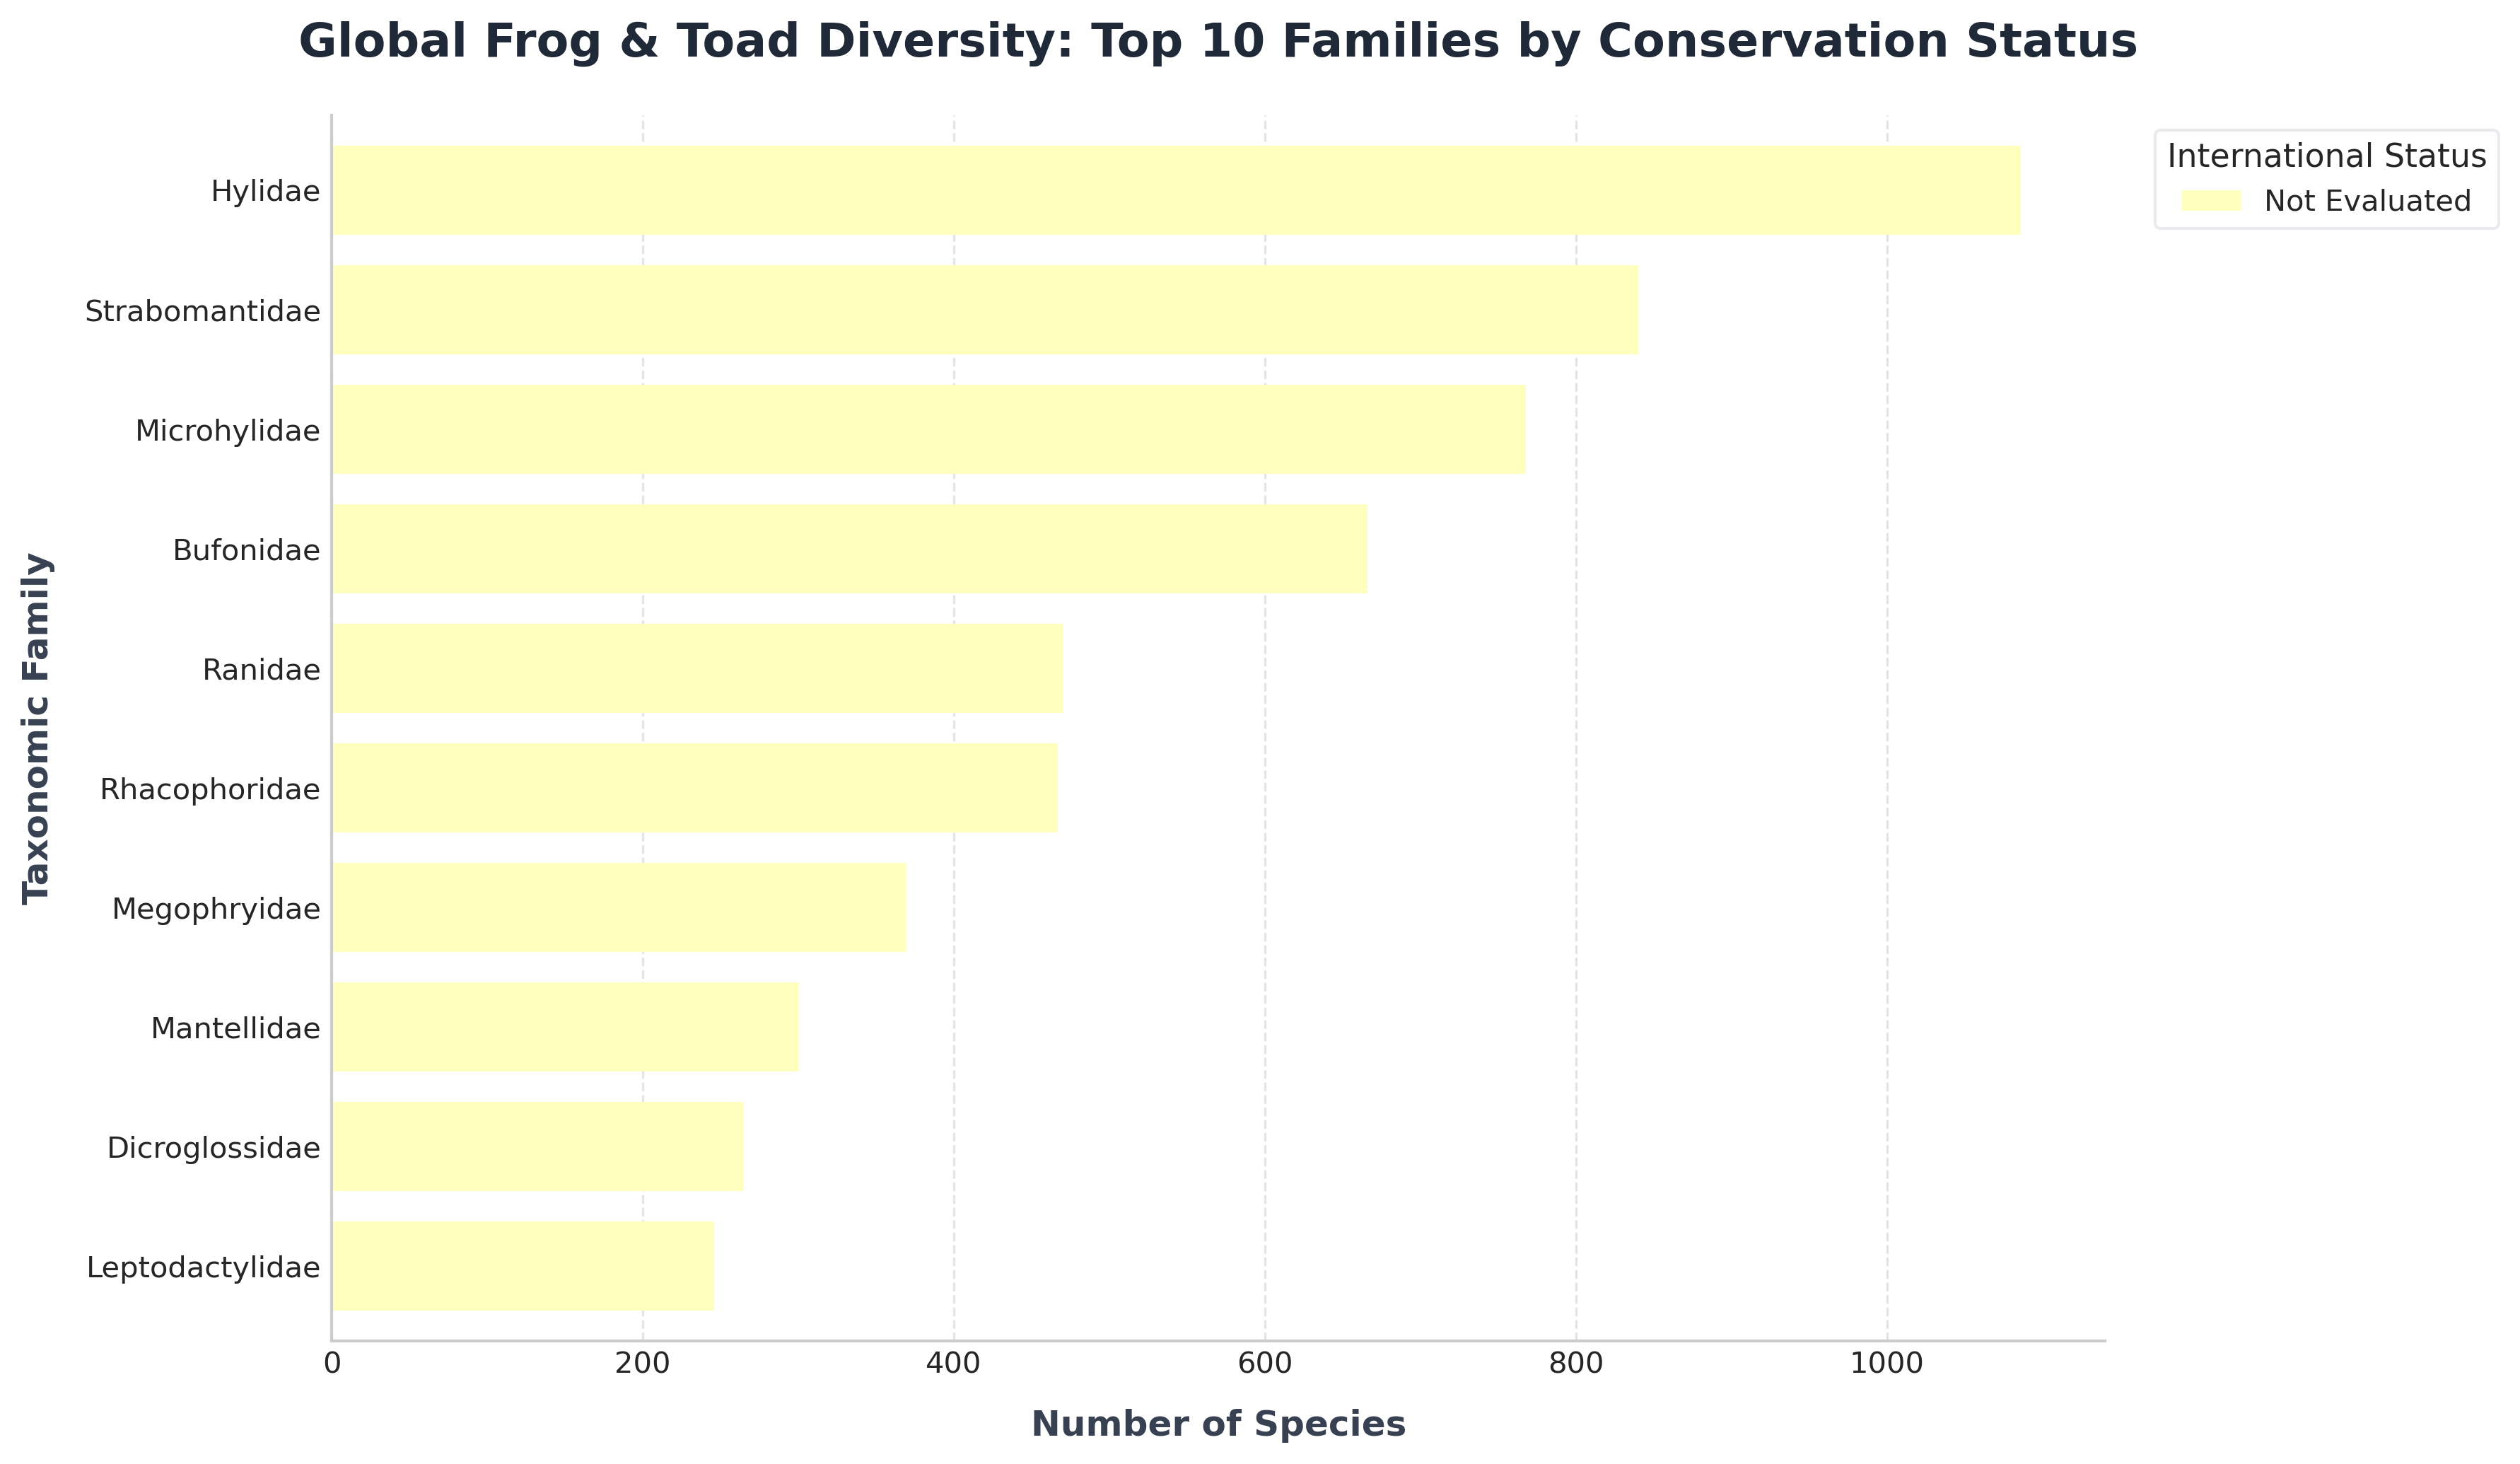

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load the dataset directly from the TidyTuesday GitHub repository
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-10-13/frogs_and_toads_amphibiaweb.csv"
print("Loading dataset...")
df = pd.read_csv(url)

# 2. Data Preparation & Cleaning
# Drop rows where family or interntnl_status is missing
df_clean = df.dropna(subset=["family"]).copy()

# Fill missing conservation status with 'Not Evaluated / Unknown'
df_clean["interntnl_status"] = (
    df_clean["interntnl_status"].fillna("Not Evaluated").str.strip()
)

# Find the top 10 most species-rich families
top_families = df_clean["family"].value_counts().nlargest(10).index.tolist()
df_filtered = df_clean[df_clean["family"].isin(top_families)]

# Create a cross-tabulation of Family vs. International Status
status_order = [
    "Least Concern",
    "Near Threatened",
    "Vulnerable",
    "Endangered",
    "Critically Endangered",
    "Extinct",
    "Data Deficient",
    "Not Evaluated",
]
# Keep only status categories present in the data or the defined order
existing_statuses = [
    s for s in status_order if s in df_filtered["interntnl_status"].unique()
]
# Add any other unexpected statuses found in the dataset
other_statuses = [
    s
    for s in df_filtered["interntnl_status"].unique()
    if s not in existing_statuses
]
all_statuses = existing_statuses + other_statuses

ct = pd.crosstab(
    df_filtered["family"], df_filtered["interntnl_status"]
)[all_statuses]

# Sort families by total species count (ascending for bottom-to-top display in horizontal bar chart)
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=True).index]

# 3. Visualization Setup
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, ax = plt.subplots(figsize=(12, 7), dpi=300)

# Custom color palette for IUCN / conservation statuses
colors = sns.color_palette("Spectral", n_colors=len(all_statuses))

# Plot horizontal stacked bar chart
ct.plot(
    kind="barh",
    stacked=True,
    ax=ax,
    color=colors,
    edgecolor="none",
    width=0.75,
)

# 4. Styling and Polish
ax.set_title(
    "Global Frog & Toad Diversity: Top 10 Families by Conservation Status",
    fontsize=16,
    fontweight="bold",
    pad=20,
    color="#1f2937",
)
ax.set_xlabel("Number of Species", fontsize=12, fontweight="bold", labelpad=10, color="#374151")
ax.set_ylabel("Taxonomic Family", fontsize=12, fontweight="bold", labelpad=10, color="#374151")

# Customize ticks and grid
ax.tick_params(axis="both", which="major", labelsize=10)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", linestyle="--", alpha=0.5)

# Format legend
ax.legend(
    title="International Status",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="#e5e7eb",
    fontsize=10,
    title_fontsize=11,
)

# Clean up spines
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()

# 5. Save and Show
plt.savefig("frogs_conservation_diversity.png", dpi=300, bbox_inches="tight")
print("Chart successfully saved as 'frogs_conservation_diversity.png'!")
plt.show()